<a href="https://colab.research.google.com/github/kvikaee/machine-learning/blob/main/ML_3_%D0%9A%D0%BE%D1%88%D1%83%D1%80%D0%B8%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Деревья решений и композиции

In [ ]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
from pathlib import Path
from pprint import pprint


В этой лабораторной вам предстоит поработать с двумя задачами сразу: классификацией и регрессией. Задача классификации в машинном обучении - это один из основных типов задач, где модель обучается предсказывать категориальную метку или класс для заданного входного наблюдения на основе обучающего набора данных, содержащего пары "входные данные - целевая метка".

Можно выделить несколько видов классификации:

* Binary - целевой признак имеет метку 0/1;
* Multiclass - целевой признак имеет метку из ограниченного множества (0, 1, 2, 3...);
* Multilabel - целевой признак может иметь несколько меток одновременно.

Классификацию можно решать как задачу регрессии (задача предсказания значения из непрерывного множества), затем выбирая порог - всем значениям меньше порога будет присвоена метка 0, всем значениям выше - метка 1.

# Деревья решений

Решающие деревья - алгоритм машинного обучения, с помощью которого можно решать задачи классификации и регрессии. Основная идея алгортитма - это поиск условий принятия решений по тренировочным данным.

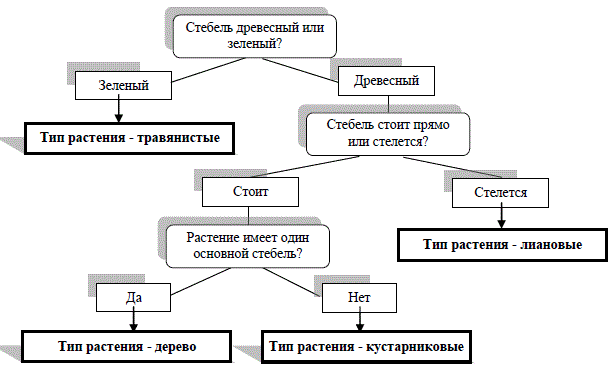

По сути, мы рекурсивно разбиваем наши обучающие данные по значениям определенного столбца, чтобы по итогу в каждом листе оказались наиболее однородные значения целевой переменной.

## Построение дерева

Опишем жадный алгоритм построения бинарного дерева решений:
1. Начинаем со всей обучающей выборки $X$, которую помещаем в корень $R_1$.
2. Задаём функционал качества $Q(X, j, t)$ и критерий остановки.
3. Запускаем построение из корня: $SplitNode(1, R_1)$

Функция $SplitNode(m, R_m)$
1. Если выполнен критерий остановки, то выход.
2. Находим наилучший с точки зрения $Q$ предикат: $j, t$: $[x_j<t]$
3. Помещаем предикат в вершину и получаем с его помощью разбиение $X$ на две части: $R_{left} = \lbrace x|x_j<t \rbrace$ и $R_{right} = \lbrace x|x_j \geqslant t \rbrace$
4. Поместим $R_{left}$ и $R_{right}$ соответсвенно в левое и правое поддерево.
5. Рекурсивно повторяем $SplitNode(left, R_{left})$ и $SplitNode(right, R_{right})$.

В конце поставим в соответствие каждому листу ответ. Для задачи классификации - это самый частый среди объектов класс или вектор с долями классов (можно интерпретировать как вероятности):
$$ c_v = \arg \max_{k\in Y} \sum_{(x_i,y_i) \in R_v} [y_i=k]  $$


Небольшое дополнение, чтобы стало понятнее: $Q$ - это функционал, который определяет то, что мы называем "наилучшим разбиением" для данных на каждом шаге. То есть мы выбираем один столбец, потом для него выбираем число $t$ такое, что часть значений столбца меньше $t$, а оставшаяся часть - больше или равна (дерево работает только с числовыми значениями или с категориальными, если они переведены в числовой формат), и смотрим, что случилось с целевой переменной при таком разбиении. Если допустить, что целевая переменная бинарная (0/1) и до разбиения нолики и единички лежали кучей, то после разбиения мы в идеале хотим получить две кучки, где в одной только нули, а в другой только единицы.

## Функционал качества для деревьев решений


Для классификации чаще всего предлагают следующие два:

- энтропия Шеннона: $-\sum_k{p_{ik}log_2(p_{ik})}$

- индекс Джини: $\sum_{j\neq k}p_{ij}p_{ik} = 1 - \sum_k p_{ik}^2$

где:

* $i$ - ID узлов дерева;

* $k, j$ - идентификаторы классов, представленных в датасете;

* $p_{ik} = \frac{N_{ik}}{N_i}$,

* $p_{ik}$ - вероятность принадлежности класса $k$ узлу $i$,

* $N_{ik}$ - число объектов класса $k$ в узле $i$,

* $N_{i}$ - общее число объектов в узле $i$.



Оба функционала позволяют определить степень хаоса в системе. Интуитивно:
* 0101101010101 - высокая степень хаоса
* 0000010010000 - средняя степень хаоса
* 0000000000000 - низкая степень хаоса

И с помощью дерева для целевой переменной мы хотим добиться чего-то вроде:
0001100011111 -> 00011000 + 11111 -> 000 + 11000 + 11111 -> 000 + 11 + 000 + 11111

Для регрессии в качестве функциона качества можно использовать, например, MSE: $\frac{1}{N_i} \sum_{j=1}^{N_i} (y_j - \bar{y}_i)^2$

где:
* $i$ — ID узла дерева;
* $N_i$ — число объектов в узле $i$;
* $y_j$ — значение целевой переменной для объекта $j$;
* $\bar{y}_i$ — среднее значение ответов в узле, которое вычисляется как:
$$\bar{y}_i = \frac{1}{N_i} \sum_{j=1}^{N_i} y_j$$

Если в классификации индекс Джини или энтропия показыват степень хаоса в распределении меток, то в регрессии MSE показывает дисперсию ответов. Чем ниже значение, тем более похожи числа в узле друг на друга. Другими словами, в задаче классификации мы измеряем чистоту классов, а в регрессии – однородность числовых значений. Поэтому при поиске лучшего разбиения признаки и пороги подбираются так, чтобы минимизировать сумму MSE в левом и правом листьях.

Реализуйте функционалы.

In [ ]:
def entropy(y):  # y - массив значений целевой переменной
    y = np.asarray(y)
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return -np.sum(p * np.log2(p))


def gini_index(y):
    y = np.asarray(y)
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return 1 - np.sum(p ** 2)


def mse(y):
    y = np.asarray(y, dtype=float)
    if len(y) == 0:
        return 0.0
    return np.mean((y - np.mean(y)) ** 2)


In [ ]:
print(entropy([0, 1, 0, 1, 0, 1]))
print(entropy([0, 0, 0, 0, 0, 1]))
print(gini_index([0, 0, 0, 0, 0, 1]))
print(mse([1, 2, 3]))

1.0
0.6500224216483541
0.2777777777777777
0.6666666666666666


In [ ]:
# tests

assert np.isclose(entropy([0, 1, 0, 1, 0, 1]), 1.0)
assert np.isclose(entropy([0, 0, 0, 0, 0, 1]), 0.65, rtol=1e5)
assert np.isclose(entropy([0, 1, 2, 0, 1, 2, 0, 1, 2]), 1.58, rtol=1e5)

assert np.isclose(gini_index([0, 1, 0, 1, 0, 1]), 0.5)
assert np.isclose(gini_index([0, 0, 0, 0, 0, 1]), 0.27, rtol=1e5)
assert np.isclose(gini_index([0, 1, 2, 0, 1, 2, 0, 1, 2]), 0.66, rtol=1e5)

assert np.isclose(mse([5, 5, 5, 5]), 0.0)
assert np.isclose(mse([1, 2, 3]), 0.66, atol=1e5)
assert np.isclose(mse([0, 10, 20]), 66.66, atol=1e5)

assert entropy([0, 0, 0, 0, 0, 0]) == gini_index([0, 0, 0, 0, 0, 0]) == mse([0, 0, 0, 0, 0, 0]) == 0.0

print("All tests passed successfully!")

All tests passed successfully!


Энтропия – по сути степень хаоса (или неопределенности) в системе. Уменьшение энтропии называют приростом информации (information gain, IG).

Обочначим $R_v$ - объекты, которые нужно разделить в помощью предиката в вершине $v$. Запишем формулу для расчёта информационного прироста:
$$ Q = IG = H(R_v) - (H(R_{left})+H(R_{right}))$$

На каждом шаге нам нужно максимизировать этот функционал качества. Как это делать? Например, можно перебрать $t$ для выбранного $j$.

Предыдущая версия формулы прироста информации слишком упрощена. В работе необходимо использовать более устойчивую формулу, которая учитывает не только энтропию подмножеств, но и их размер.

$$ Q = IG = H(R_v) - \Big (\frac{|R_{left}|} {|R_{v}|} H(R_{left})+ \frac{|R_{right}|} {|R_{v}|} H(R_{right})\Big)$$

где, $|R_{v}|$, $|R_{left}|$ и $|R_{right}|$ - количество элементов в соответствующих множествах.


## Задание 1 (5 баллов)

### Задание 1.1: Классификация

Реализуйте алгоритм построения дерева. Должны быть отдельные функции (методы) для расчёта энтропии (уже есть), для разделения узлов дерева (используйте, например, `pandas`), для подсчёта функционала качества $IG$, для выбора наилучшего разделения (с учетом признаков и порогов), для проверки критерия остановки.

Для набора данных `iris` реализуйте алгоритм и минимум три разных критерия остановки из перечисленных ниже:
* максимальной глубины дерева = 5
* минимального числа объектов в листе = 5
* максимальное количество листьев в дереве = 5
* purity (остановка, если все объекты в листе относятся к одному классу)

В классе `Tree` реализуйте метод `predict` (на вход метода подаётся датафрейм с объектами)

Оцените точность каждой модели с помощью метрики доля правильных ответов (`from sklearn.metrics import accuracy_score` или реализовать свою). Обратите внимание на то, что классы в датасете представлены одинаковым количеством объектов.

In [ ]:
class TreeNode:
    def __init__(self, feature=None, threshold=None, left=None, right=None,
                 value=None, depth=0, n_samples=0, gain=0.0):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
        self.depth = depth
        self.n_samples = n_samples
        self.gain = gain

    @property
    def is_leaf(self):
        return self.left is None and self.right is None


class Tree:
    def __init__(self, max_depth=None, min_samples_leaf=1, max_leaves=None,
                 criterion='entropy', purity=False, random_state=42):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_leaves = max_leaves
        self.criterion = criterion
        self.purity = purity
        self.random_state = random_state

        self.root = None
        self.feature_names_in_ = None
        self.feature_importances_ = None

    def _impurity(self, y):
        if self.criterion == 'entropy':
            return entropy(y)
        if self.criterion == 'gini':
            return gini_index(y)
        raise ValueError(f"Unknown criterion: {self.criterion!r}")

    def _split(self, X, y, feature, threshold):
        left_mask = X[feature] <= threshold
        return (X[left_mask], y[left_mask],
                X[~left_mask], y[~left_mask])

    def _information_gain(self, y, y_left, y_right):
        n = len(y)
        n_left, n_right = len(y_left), len(y_right)
        parent = self._impurity(y)
        weighted = (n_left * self._impurity(y_left) +
                    n_right * self._impurity(y_right)) / n
        return parent - weighted

    def _best_split(self, X, y):
        best = {'feature': None, 'threshold': None, 'gain': 0.0,
                'left_mask': None}
        for feature in X.columns:
            values = np.unique(X[feature].to_numpy())
            if len(values) < 2:
                continue
            thresholds = (values[:-1] + values[1:]) / 2
            for t in thresholds:
                left_mask = X[feature] <= t
                n_left = int(left_mask.sum())
                n_right = len(X) - n_left
                if (n_left < self.min_samples_leaf
                        or n_right < self.min_samples_leaf):
                    continue
                gain = self._information_gain(y, y[left_mask], y[~left_mask])
                if gain > best['gain']:
                    best = {'feature': feature, 'threshold': t,
                            'gain': gain, 'left_mask': left_mask}
        return best

    def _should_stop(self, y, depth):
        classes = np.unique(y)

        if self.purity and len(classes) == 1:
            return True

        if len(classes) == 1:
            return True

        if self.max_depth is not None and depth >= self.max_depth:
            return True

        if len(y) < 2 * self.min_samples_leaf:
            return True

        return False

    @staticmethod
    def _majority(y):
        return pd.Series(y).value_counts().idxmax()

    def _build(self, X, y, depth):
        node = TreeNode(depth=depth, n_samples=len(y),
                        value=self._majority(y))

        if self._should_stop(y, depth):
            return node

        split = self._best_split(X, y)
        if split['feature'] is None:
            return node

        node.feature = split['feature']
        node.threshold = split['threshold']
        node.gain = split['gain']

        X_left, y_left, X_right, y_right = self._split(
            X, y, split['feature'], split['threshold'])

        node.left = self._build(X_left, y_left, depth + 1)
        node.right = self._build(X_right, y_right, depth + 1)
        return node

    def _count_leaves(self, node):
        if node is None:
            return 0
        if node.is_leaf:
            return 1
        return self._count_leaves(node.left) + self._count_leaves(node.right)

    def _collect_internal(self, node, out):
        if node is None or node.is_leaf:
            return
        out.append(node)
        self._collect_internal(node.left, out)
        self._collect_internal(node.right, out)

    def _prune_to_max_leaves(self):
        if self.max_leaves is None:
            return
        while self._count_leaves(self.root) > self.max_leaves:
            internal = []
            self._collect_internal(self.root, internal)
            if not internal:
                break
            weakest = min(internal, key=lambda n: n.gain)
            weakest.left = None
            weakest.right = None
            weakest.feature = None
            weakest.threshold = None

    def fit(self, X, y):
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X)
        if not isinstance(y, pd.Series):
            y = pd.Series(np.asarray(y))
        y = y.reset_index(drop=True)
        X = X.reset_index(drop=True)

        self.feature_names_in_ = list(X.columns)
        self.root = self._build(X, y, 0)
        self._prune_to_max_leaves()
        self._compute_importances()
        return self

    def _compute_importances(self):
        importances = {f: 0.0 for f in self.feature_names_in_}

        def walk(node):
            if node is None or node.is_leaf:
                return
            importances[node.feature] += node.n_samples * node.gain
            walk(node.left)
            walk(node.right)

        walk(self.root)
        total = sum(importances.values())
        self.feature_importances_ = pd.Series(
            {k: (v / total if total > 0 else 0.0)
             for k, v in importances.items()})

    def _predict_one(self, x, node):
        while not node.is_leaf:
            node = node.left if x[node.feature] <= node.threshold else node.right
        return node.value

    def predict(self, X):
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X, columns=self.feature_names_in_)
        return np.array([self._predict_one(row, self.root)
                         for _, row in X.iterrows()])

Один из варинтов того, как может выглядеть дерево (в данном случае переобученное).

Вам не обязательно реализовывать функционал для визуализации, это просто пример. Но если хочется - посмотрите в сторону библиотеки [graphviz](https://graphviz.org/).


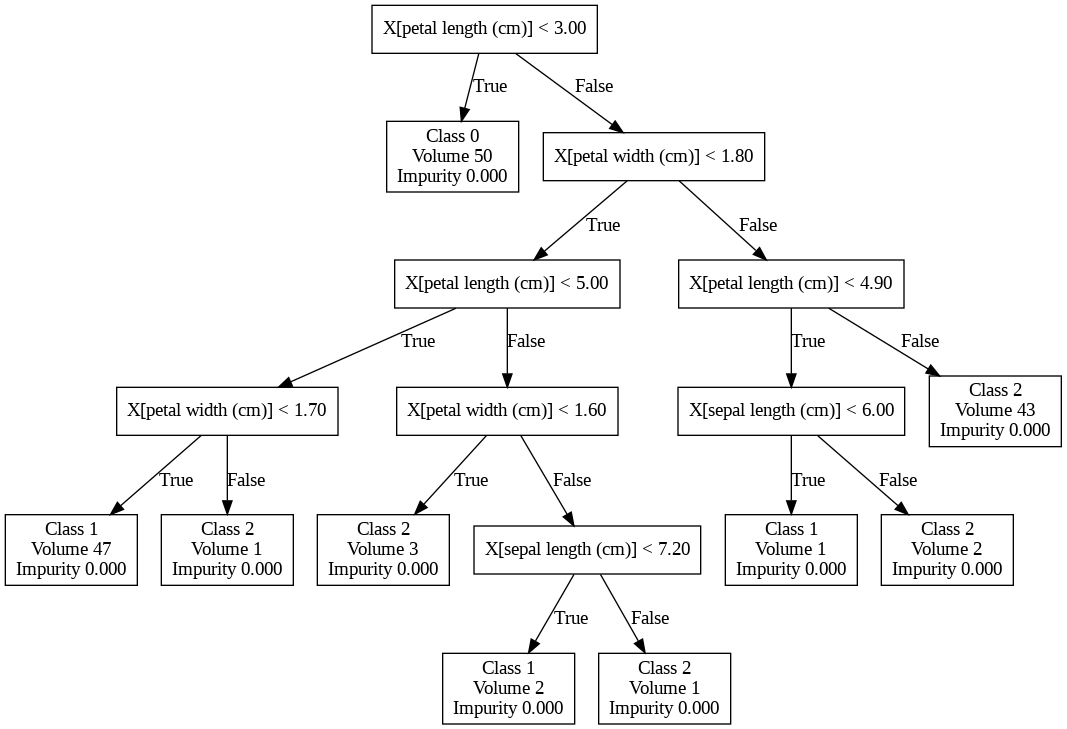

In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split  # при оценке вашего алгоритма не забудьте разбить данные на тренировочную и тестовую выборки
from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.tree import DecisionTreeClassifier  # можете сравнить качество вашего алгоритма с реализацией "из коробки"


iris = datasets.load_iris()
X = iris['data']
feature_names = iris['feature_names']
y = iris['target']
target_names = iris['target_names']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

tree = Tree(
    max_depth=5,
    min_samples_leaf=5,
    max_leaves=5,
    criterion='gini',
    purity=True
)

print("до обучения:")
print(tree.root)

tree.fit(X_train, y_train)

print("\nпосле обучения:")
print("признак в корне:", tree.root.feature)
print("порог в корне:", tree.root.threshold)

y_pred = tree.predict(X_test)

print("\nпервые 10 предсказаний:", y_pred[:10])
print("первые 10 правильных ответов:", y_test[:10])

accuracy = accuracy_score(y_test, y_pred)

print("\naccuracy:", accuracy)


print("\n" + "=" * 60)
print("Сравнение критериев остановки (criterion='gini')")
print("=" * 60)

configs = [
    ("max_depth=5",        dict(max_depth=5)),
    ("min_samples_leaf=5", dict(min_samples_leaf=5)),
    ("max_leaves=5",       dict(max_leaves=5)),
    ("purity=True",        dict(purity=True)),
]

print(f"{'критерий':<22s} {'accuracy':>10s} {'листьев':>10s}")
for name, cfg in configs:
    t = Tree(criterion='gini', **cfg).fit(X_train, y_train)
    pred = t.predict(X_test)
    acc = accuracy_score(y_test, pred)
    leaves = t._count_leaves(t.root)
    print(f"{name:<22s} {acc:>10.4f} {leaves:>10d}")


print("\n" + "=" * 60)
print("Важность признаков (модель из шаблона)")
print("=" * 60)

X_df = pd.DataFrame(iris.data, columns=iris.feature_names)
y_sr = pd.Series(iris.target, name='target')

X_train_df, X_test_df, y_train_sr, y_test_sr = train_test_split(
    X_df, y_sr,
    test_size=0.25,
    random_state=42,
    stratify=y_sr
)

tree_named = Tree(
    max_depth=5,
    min_samples_leaf=5,
    max_leaves=5,
    criterion='gini',
    purity=True
).fit(X_train_df, y_train_sr)

importances = tree_named.feature_importances_.sort_values(ascending=False)
print(importances.to_string())


print("\n" + "=" * 60)
print("Сравнение с sklearn.tree.DecisionTreeClassifier")
print("=" * 60)

from sklearn.tree import DecisionTreeClassifier

sk = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=5,
    criterion='gini',
    random_state=42
)
sk.fit(X_train, y_train)
sk_acc = accuracy_score(y_test, sk.predict(X_test))

print(f"{'наша реализация':<22s} {accuracy:>10.4f}")
print(f"{'sklearn':<22s} {sk_acc:>10.4f}")

до обучения:
None

после обучения:
признак в корне: 2
порог в корне: 2.45

первые 10 предсказаний: [0 1 1 1 0 1 2 2 2 2]
первые 10 правильных ответов: [0 1 1 1 0 1 2 2 2 2]

accuracy: 0.9210526315789473

Сравнение критериев остановки (criterion='gini')
критерий                 accuracy    листьев
max_depth=5                0.8947          8
min_samples_leaf=5         0.9211          5
max_leaves=5               0.9211          3
purity=True                0.8947          9

Важность признаков (модель из шаблона)
petal length (cm)    0.963733
petal width (cm)     0.036267
sepal width (cm)     0.000000
sepal length (cm)    0.000000

Сравнение с sklearn.tree.DecisionTreeClassifier
наша реализация            0.9211
sklearn                    0.8947


### Задание 1.2: Регрессия

Напишите класс `TreeRegressor`, модифицировав класс `Tree` под решение задачи регрессии.

Протестируйте и оцените работу класса на задаче предсказания продолжительности жизни: https://www.kaggle.com/datasets/byazitmustafayev/life-expectancy-factors-2000-2019

Часть признаков в датасете требует предобработки. Проведите ее и обоснуйте.

Критерии остановки используйте те же, что в задании 1.1, но с поправкой на регрессию.

Для оценки качества предсказания выберите не менее трех метрик.

In [ ]:
class TreeRegressor:
    def __init__(self, max_depth=None, min_samples_leaf=1, max_leaves=None,
                 random_state=42):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_leaves = max_leaves
        self.random_state = random_state
        self.root = None
        self.feature_names_in_ = None
        self.feature_importances_ = None

    def _impurity(self, y):
        return mse(y)

    def _best_split(self, X, y):
        n = len(y)
        if n == 0:
            return None, None, 0.0

        parent = self._impurity(y)
        best_gain = 0.0
        best_feature = None
        best_threshold = None

        total_sum = np.sum(y)
        total_sq_sum = np.sum(y ** 2)

        for j in range(X.shape[1]):
            order = np.argsort(X[:, j])
            x_sorted = X[order, j]
            y_sorted = y[order]

            if np.all(x_sorted == x_sorted[0]):
                continue

            csum = np.cumsum(y_sorted)
            csq = np.cumsum(y_sorted ** 2)

            split_positions = np.where(x_sorted[:-1] < x_sorted[1:])[0] + 1
            split_positions = split_positions[
                (split_positions >= self.min_samples_leaf) &
                ((n - split_positions) >= self.min_samples_leaf)
            ]
            if len(split_positions) == 0:
                continue

            for k in split_positions:
                n_left = k
                n_right = n - k

                left_sum = csum[k - 1]
                left_sq = csq[k - 1]
                right_sum = total_sum - left_sum
                right_sq = total_sq_sum - left_sq

                left_mse = left_sq / n_left - (left_sum / n_left) ** 2
                right_mse = right_sq / n_right - (right_sum / n_right) ** 2
                weighted = (n_left * left_mse + n_right * right_mse) / n
                gain = parent - weighted

                if gain > best_gain:
                    best_gain = gain
                    best_feature = j
                    best_threshold = (x_sorted[k - 1] + x_sorted[k]) / 2

        return best_feature, best_threshold, best_gain

    def _should_stop(self, y, depth):
        if len(y) == 0:
            return True
        if np.allclose(y, y[0]):
            return True
        if self.max_depth is not None and depth >= self.max_depth:
            return True
        if len(y) < 2 * self.min_samples_leaf:
            return True
        return False

    def _build(self, X, y, depth):
        node = TreeNode(depth=depth, n_samples=len(y))
        node.value = float(np.mean(y)) if len(y) > 0 else 0.0

        if self._should_stop(y, depth):
            return node

        feature, threshold, gain = self._best_split(X, y)
        if feature is None or gain <= 0:
            return node

        node.feature = feature
        node.threshold = threshold
        node.gain = gain

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        node.left = self._build(X[left_mask], y[left_mask], depth + 1)
        node.right = self._build(X[right_mask], y[right_mask], depth + 1)
        return node

    def _count_leaves(self, node):
        if node is None:
            return 0
        if node.is_leaf:
            return 1
        return self._count_leaves(node.left) + self._count_leaves(node.right)

    def _collect_internal(self, node, out):
        if node is None or node.is_leaf:
            return
        out.append(node)
        self._collect_internal(node.left, out)
        self._collect_internal(node.right, out)

    def _prune_to_max_leaves(self):
        if self.max_leaves is None:
            return
        while self._count_leaves(self.root) > self.max_leaves:
            internal = []
            self._collect_internal(self.root, internal)
            if not internal:
                break
            weakest = min(internal, key=lambda n: n.gain)
            weakest.left = None
            weakest.right = None
            weakest.feature = None
            weakest.threshold = None

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            self.feature_names_in_ = list(X.columns)
            X = X.to_numpy(dtype=float)
        else:
            X = np.asarray(X, dtype=float)
            self.feature_names_in_ = list(range(X.shape[1]))

        y = np.asarray(y, dtype=float)

        if len(X) != len(y):
            raise ValueError("X and y have different lengths")

        self.root = self._build(X, y, 0)
        self._prune_to_max_leaves()
        self._compute_importances()
        return self

    def _compute_importances(self):
        importances = np.zeros(len(self.feature_names_in_))

        def walk(node):
            if node is None or node.is_leaf:
                return
            importances[node.feature] += node.n_samples * node.gain
            walk(node.left)
            walk(node.right)

        walk(self.root)
        total = importances.sum()
        if total > 0:
            importances /= total
        self.feature_importances_ = pd.Series(importances,
                                              index=self.feature_names_in_)

    def _predict_one(self, x, node):
        while not node.is_leaf:
            node = node.left if x[node.feature] <= node.threshold else node.right
        return node.value

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.to_numpy(dtype=float)
        else:
            X = np.asarray(X, dtype=float)

        if self.root is None:
            raise RuntimeError("Model is not fitted yet")

        return np.array([self._predict_one(x, self.root) for x in X])

In [ ]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

life_path = Path('/content/life expectancy.csv')
life = pd.read_csv(life_path)

life.columns = life.columns.str.strip()

target = 'Life_Expectancy'

life[target] = pd.to_numeric(life[target], errors='coerce')

life['Year'] = life['Year'].astype(str).str.extract(r'(\d{4})')[0].astype(float)

numeric_cols = [c for c in life.columns
                if c not in ['Country Name', 'Country Code', target, 'Year']]
for col in numeric_cols:
    life[col] = pd.to_numeric(life[col], errors='coerce')

life = life.dropna(subset=[target]).copy()

life = life.drop(columns=['index', 'Country Code'], errors='ignore')

if 'Country Name' in life.columns:
    life = life.drop(columns=['Country Name'])

for col in life.columns:
    if life[col].isna().any():
        life[col] = life[col].fillna(life[col].median())

life = life.dropna(axis=1, how='all')

X_life = life.drop(columns=[target])
y_life = life[target]

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_life, y_life, test_size=0.2, random_state=42
)

In [ ]:
reg_tree = TreeRegressor(max_depth=5, min_samples_leaf=5, random_state=42)
reg_tree.fit(X_train_l, y_train_l)

pred_l = reg_tree.predict(X_test_l)

mae = mean_absolute_error(y_test_l, pred_l)
rmse = np.sqrt(mean_squared_error(y_test_l, pred_l))
r2 = r2_score(y_test_l, pred_l)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2:   {r2:.3f}")
print(f"Листьев: {reg_tree._count_leaves(reg_tree.root)}")

print("\nВажность признаков:")
print(reg_tree.feature_importances_.sort_values(ascending=False).head(10).to_string())

MAE:  2.124
RMSE: 2.978
R2:   0.871
Листьев: 25

Важность признаков:
Tertiary_School_Enrollment       0.665066
Health_Expenditure_Per_Capita    0.276206
Population_Density               0.040364
Urban_Population_Rate            0.008695
Year                             0.005741
Political_Stability_Index        0.002702
PM25_AirPollution                0.001227


In [ ]:
print("\nСравнение критериев остановки:")
print(f"{'модель':<22s} {'MAE':>8s} {'RMSE':>8s} {'R2':>8s} {'листьев':>9s}")

configs = [
    ('max_depth=5',        dict(max_depth=5)),
    ('min_samples_leaf=5', dict(min_samples_leaf=5)),
    ('max_leaves=5',       dict(max_leaves=5)),
    ('purity',             dict()),
]

for name, cfg in configs:
    t = TreeRegressor(**cfg).fit(X_train_l, y_train_l)
    p = t.predict(X_test_l)
    print(f"{name:<22s} "
          f"{mean_absolute_error(y_test_l, p):>8.3f} "
          f"{np.sqrt(mean_squared_error(y_test_l, p)):>8.3f} "
          f"{r2_score(y_test_l, p):>8.3f} "
          f"{t._count_leaves(t.root):>9d}")


Сравнение критериев остановки:
модель                      MAE     RMSE       R2   листьев
max_depth=5               2.130    2.976    0.871        31
min_samples_leaf=5        1.373    2.290    0.924       300
max_leaves=5              3.389    4.428    0.715         5
purity                    1.070    2.138    0.934      1836


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# нам нужно сохранить страны, чтобы делить по ним
life_with_country = pd.read_csv(life_path)
life_with_country.columns = life_with_country.columns.str.strip()
life_with_country['Year'] = life_with_country['Year'].astype(str).str.extract(r'(\d{4})')[0].astype(float)
life_with_country[target] = pd.to_numeric(life_with_country[target], errors='coerce')
life_with_country = life_with_country.dropna(subset=[target])

# те же признаки, что в основном эксперименте
feature_cols = ['PM25_AirPollution', 'Population_Density',
                'Political_Stability_Index', 'Tertiary_School_Enrollment',
                'Health_Expenditure_Per_Capita', 'Year', 'Urban_Population_Rate']
feature_cols = [c for c in feature_cols if c in life_with_country.columns]

X_full = life_with_country[feature_cols].apply(pd.to_numeric, errors='coerce')
y_full = life_with_country[target]
groups = life_with_country['Country Name']

X_full = X_full.fillna(X_full.median())

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X_full, y_full, groups=groups))

X_tr, X_te = X_full.iloc[train_idx], X_full.iloc[test_idx]
y_tr, y_te = y_full.iloc[train_idx], y_full.iloc[test_idx]

t = TreeRegressor(max_depth=5, min_samples_leaf=5, random_state=42).fit(X_tr, y_tr)
p = t.predict(X_te)

print(f"GroupShuffleSplit (честно):")
print(f"  MAE  = {mean_absolute_error(y_te, p):.3f}")
print(f"  RMSE = {np.sqrt(mean_squared_error(y_te, p)):.3f}")
print(f"  R2   = {r2_score(y_te, p):.3f}")
print(f"  Уникальных стран в train: {groups.iloc[train_idx].nunique()}")
print(f"  Уникальных стран в test:  {groups.iloc[test_idx].nunique()}")

GroupShuffleSplit (честно):
  MAE  = 2.896
  RMSE = 4.624
  R2   = 0.752
  Уникальных стран в train: 143
  Уникальных стран в test:  36


In [ ]:
from sklearn.tree import DecisionTreeRegressor

sk = DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=42)
sk.fit(X_train_l, y_train_l)
sk_pred = sk.predict(X_test_l)

print("\nСравнение со sklearn (max_depth=5, min_samples_leaf=5):")
print(f"{'наша реализация':<22s} "
      f"{mae:>8.3f} {rmse:>8.3f} {r2:>8.3f} "
      f"{reg_tree._count_leaves(reg_tree.root):>9d}")
print(f"{'sklearn':<22s} "
      f"{mean_absolute_error(y_test_l, sk_pred):>8.3f} "
      f"{np.sqrt(mean_squared_error(y_test_l, sk_pred)):>8.3f} "
      f"{r2_score(y_test_l, sk_pred):>8.3f} "
      f"{sk.get_n_leaves():>9d}")


Сравнение со sklearn (max_depth=5, min_samples_leaf=5):
наша реализация           2.124    2.978    0.871        25
sklearn                   2.124    2.978    0.871        25


#  [Ансамбли](https://education.yandex.ru/handbook/ml/article/ansambli-v-mashinnom-obuchenii)




Суть ансамблей заключается в том, чтобы объединить предсказания стандартных моделей для повышения обобщающей способности или надёжности ансамбля перед одиночным стандартным методом машинного обучения.

Можно выделить следующие типы ансамблирования:

* Бэггинг. Однотипная модель строится по различным подвыборкам обучающих данных, затем результаты аггрегируются, например, с помощью усреднения. Для деревьев решений очень распространенным алгоритмом, использующим идею бэггинга, является случайный лес.

* Бустинг. Строится последовательность однотипных моделей, где каждая следующая призвана исправлять ошибки предыдущих. Самым распространенным алгоритмом бустинга является градиентный бустинг.

* Стэкинг. Строится несколько моделей разного типа, а также мета-модель, делающая итоговое предсказание на основании предсказаний моделей.

Для последующих заданий в качестве набора данных используйте: https://www.kaggle.com/mathchi/churn-for-bank-customers

Там есть описание и примеры работы с этими данными. Если кратко, речь идёт про задачу прогнозирования оттока клиентов. Есть данные о 10 тысячах клиентов банка, часть из которых больше не являются клиентами.

Обратите внимание, что данные нуждаются в небольшой предобаботке, так как деревья работают только с числовыми признаками.


### Задание 2.1 (2 балла)

Опишем алгоритм случайный лес (*random forest*) и попутно разберём основные идеи бэггинга:

1. Зададим $N$ - число деревьев в лесу.
2. Для каждого $n$ из $N$ сгенерируем свою выборку $X_n$. Пусть $m$ - это количество объектов в $X$. При генерации каждой $X_n$ мы будем брать объекты $m$ раз с возвращением. То есть один и тот же объект может попасть в выборку несколько раз, а какие-то объекты не попадут. (Этот способ назвается бутстрап).
3. По каждой $X_n$ построим решающее дерево $b_n$. Обычно стараются делать глубокие деревья. В качестве критериев остановки можно использовать `max_depth` или `min_samples_leaf` (например, пока в каждом листе не окажется по одному объекту). При каждом разбиении сначала выбирается $k$ (эвристика $k = \sqrt d$, где $d$ - это число признаков объектов из выборки $X$) случайных признаков из исходных, и оптимальное разделение выборки ищется только среди них. Обратите внимание, что мы не выбрасываем оставшиеся признаки!
4. Итоговый алгоритм будет представлять собой результат голосования (для классификации) и среднее арифметическое (для регрессии). Модификация алгоритма предполагает учёт весов каждого отдельного слабого алгоритма в ансамбле, но в этом особо нет смысла.


Используя либо свою реализацию, либо  `DecisionTreeClassifier` с разными настройками из `sklearn.tree` реализуйте алгоритм "случайный лес".

Найдите наилучшие гиперпараметры этого алгоритма: количество деревьев, критерий остановки, функционал качества и другие. Выберите метрику, по которой вы будете сравнивать качество алгоритмов и кратко обоснуйте, почему вы выбрали именно её (в письменном формате).

Нельзя использовать готовую реализацию случайного леса из `sklearn`, но можно сопоставлять с ней качество вашего алгоритма.



In [ ]:
class RandomForest:
    def __init__(self, n_estimators=100, max_depth=None, min_samples_leaf=1,
                 max_features='sqrt', bootstrap=True, task='classification',
                 random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.bootstrap = bootstrap
        self.task = task
        self.random_state = random_state
        self.trees = []
        self.feature_importances_ = None

    def fit(self, X, y):
        from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        rng = np.random.default_rng(self.random_state)
        self.trees = []

        n = len(X)
        for _ in range(self.n_estimators):
            if self.bootstrap:
                idx = rng.integers(0, n, size=n)
            else:
                idx = np.arange(n)

            if self.task == 'classification':
                tree = DecisionTreeClassifier(
                    max_depth=self.max_depth,
                    min_samples_leaf=self.min_samples_leaf,
                    max_features=self.max_features,
                    random_state=int(rng.integers(0, 1_000_000))
                )
            else:
                tree = DecisionTreeRegressor(
                    max_depth=self.max_depth,
                    min_samples_leaf=self.min_samples_leaf,
                    max_features=self.max_features,
                    random_state=int(rng.integers(0, 1_000_000))
                )

            tree.fit(X[idx], y[idx])
            self.trees.append(tree)

        self.feature_importances_ = np.mean(
            [tree.feature_importances_ for tree in self.trees], axis=0
        )
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        predictions = np.vstack([tree.predict(X) for tree in self.trees])

        if self.task == 'regression':
            return predictions.mean(axis=0)

        result = []
        for i in range(X.shape[0]):
            values, counts = np.unique(predictions[:, i], return_counts=True)
            result.append(values[np.argmax(counts)])
        return np.asarray(result)

    def predict_proba(self, X):
        if self.task != 'classification':
            raise AttributeError('predict_proba доступен только для классификации')
        X = np.asarray(X, dtype=float)
        return np.mean([tree.predict_proba(X) for tree in self.trees], axis=0)


In [ ]:
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score


# 1. загрузка
bank = pd.read_csv('/content/churn.csv')

# убираем идентификаторы, они не несут предсказательной силы
drop_cols = [c for c in ['RowNumber', 'CustomerId', 'Surname'] if c in bank.columns]
bank = bank.drop(columns=drop_cols)

# one-hot без drop_first: деревьям выгоднее видеть каждую категорию отдельным бинарным признаком
bank = pd.get_dummies(bank, columns=['Geography', 'Gender'], drop_first=False, dtype=int)

X_bank = bank.drop(columns=[target])
y_bank = bank[target]

# смотрим на баланс классов — это обосновывает выбор F1 как основной метрики
print('Распределение классов:')
print(y_bank.value_counts(normalize=True).round(3))

# стратифицированное разбиение сохраняет пропорции классов в train и test
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_bank, y_bank, test_size=0.2, random_state=42, stratify=y_bank
)


# 2. перебор гиперпараметров
results = []
for n_estimators in [50, 100, 200]:
    for max_depth in [5, 10, 15, None]:
        for min_samples_leaf in [1, 5, 10]:
            for max_features in ['sqrt', 'log2']:
                model = RandomForest(
                    n_estimators=n_estimators,
                    max_depth=max_depth,
                    min_samples_leaf=min_samples_leaf,
                    max_features=max_features,
                    task='classification',
                    random_state=42
                )
                model.fit(X_train_b, y_train_b)
                pred = model.predict(X_test_b)

                results.append({
                    'n_estimators': n_estimators,
                    'max_depth': max_depth,
                    'min_samples_leaf': min_samples_leaf,
                    'max_features': max_features,
                    'accuracy':  accuracy_score(y_test_b, pred),
                    'precision': precision_score(y_test_b, pred, zero_division=0),
                    'recall':    recall_score(y_test_b, pred, zero_division=0),
                    'f1':        f1_score(y_test_b, pred, zero_division=0),
                    'model':     model,   # сохраняем саму модель, чтобы не переобучать
                })

results_df = pd.DataFrame(results).sort_values('f1', ascending=False)
print('\nТоп-10 по F1:')
print(results_df.drop(columns=['model']).head(10).to_string(index=False))


# 3. лучшая модель
best_row = results_df.iloc[0]
rf_best = best_row['model']           # уже обученная модель, без повторного fit
best_pred = rf_best.predict(X_test_b)

print('\nЛучшая конфигурация:')
print(f"  n_estimators     = {best_row['n_estimators']}")
print(f"  max_depth        = {best_row['max_depth']}")
print(f"  min_samples_leaf = {best_row['min_samples_leaf']}")
print(f"  max_features     = {best_row['max_features']}")

print(f"\naccuracy:  {accuracy_score(y_test_b, best_pred):.3f}")
print(f"precision: {precision_score(y_test_b, best_pred, zero_division=0):.3f}")
print(f"recall:    {recall_score(y_test_b, best_pred, zero_division=0):.3f}")
print(f"f1:        {f1_score(y_test_b, best_pred, zero_division=0):.3f}")


# 4. важности признаков
importances = pd.Series(
    rf_best.feature_importances_, index=X_bank.columns
).sort_values(ascending=False)
print('\nВажность признаков (топ-10):')
print(importances.head(10).round(4).to_string())

Распределение классов:
Exited
0    0.796
1    0.204
Name: proportion, dtype: float64

Топ-10 по F1:
 n_estimators  max_depth  min_samples_leaf max_features  accuracy  precision   recall       f1
          200       15.0                 1         sqrt    0.8645   0.783333 0.461916 0.581144
          200       15.0                 1         log2    0.8645   0.783333 0.461916 0.581144
          100       15.0                 1         sqrt    0.8625   0.770492 0.461916 0.577573
          100       15.0                 1         log2    0.8625   0.770492 0.461916 0.577573
          200        NaN                 1         log2    0.8610   0.759036 0.464373 0.576220
          200        NaN                 1         sqrt    0.8610   0.759036 0.464373 0.576220
          200       15.0                10         log2    0.8675   0.828704 0.439803 0.574639
          200       15.0                10         sqrt    0.8675   0.828704 0.439803 0.574639
          200       15.0                 5   

## Задание 2.2 (1 балла)

В подобных задачах очень важна интерпретируемость алгоритма. Попытайтесь оценить информативность признаков, т.е. ответить а вопрос, значения каких признаков являются самыми важными индикаторами того, что банк потеряет клиента. Можно, например, использовать [SHAP](https://habr.com/ru/companies/wunderfund/articles/739744/) для анализа. Также основные способы для определения важности признаков моделей "из коробки" [описаны здесь](https://machinelearningmastery.com/calculate-feature-importance-with-python/).

In [ ]:
!pip install shap -q

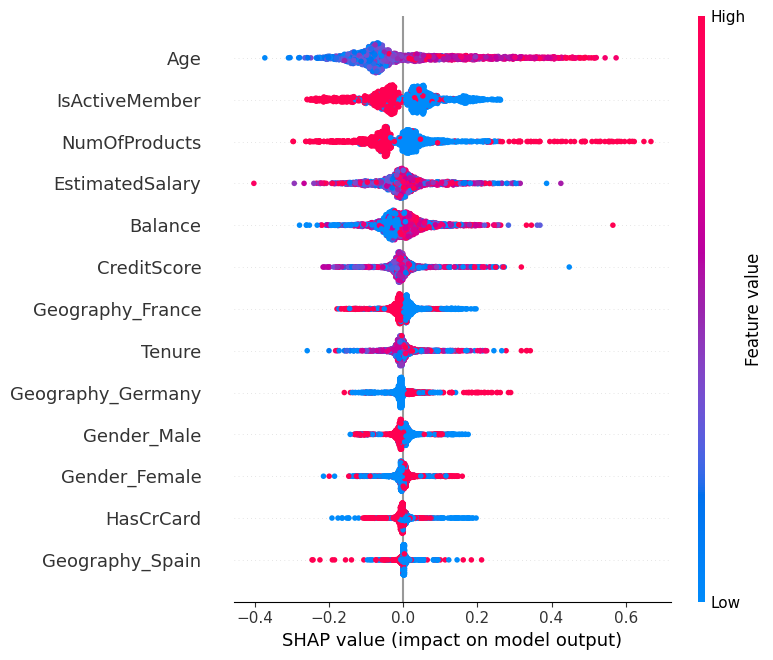

In [ ]:
import shap

# берём одно дерево из леса — это sklearn-дерево, TreeExplainer его понимает
explainer = shap.TreeExplainer(rf_best.trees[0])

# считаем SHAP-значения на тестовой выборке
shap_values = explainer.shap_values(X_test_b)

# для бинарной классификации shap_values — список из двух массивов,
# индекс 1 — вклад в класс "ушёл"
shap.summary_plot(shap_values[:, :, 1], X_test_b)

### Задание 2.3 (1 балл)

Как и в случае с деревом решений, модифицируйте свою реализацию случайного леса под решение задачи регрессии. Внутри можете использовать свою реализацию из задания 1 или `DecisionTreeRegressor` из `sklearn`.

Сравните качество решения задачи о предсказании продолжительности жизни (те же данные, что в предыдущем задании) с результатами дерева при тех же критериях остановки.

Оцените информативность признаков.

In [ ]:
rf_reg = RandomForest(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=5,
    max_features='sqrt',
    task='regression',
    random_state=42
)
rf_reg.fit(X_train_l, y_train_l)
rf_pred = rf_reg.predict(X_test_l)

print(f'Random Forest MAE: {mean_absolute_error(y_test_l, rf_pred):.3f}')
print(f'Random Forest RMSE: {np.sqrt(mean_squared_error(y_test_l, rf_pred)):.3f}')
print(f'Random Forest R2: {r2_score(y_test_l, rf_pred):.3f}')

tree_pred = reg_tree.predict(X_test_l)
print(f'Tree MAE: {mean_absolute_error(y_test_l, tree_pred):.3f}')
print(f'Tree RMSE: {np.sqrt(mean_squared_error(y_test_l, tree_pred)):.3f}')
print(f'Tree R2: {r2_score(y_test_l, tree_pred):.3f}')

life_importance = pd.Series(
    rf_reg.feature_importances_, index=X_life.columns
).sort_values(ascending=False)

display(life_importance.head(10).to_frame('importance'))


Random Forest MAE: 2.114
Random Forest RMSE: 2.845
Random Forest R2: 0.882
Tree MAE: 2.124
Tree RMSE: 2.978
Tree R2: 0.871


,importance
Health_Expenditure_Per_Capita,0.333934
Tertiary_School_Enrollment,0.319760
Urban_Population_Rate,0.162681
PM25_AirPollution,0.059853
Political_Stability_Index,0.059448
Population_Density,0.053483
Year,0.010841


## Задание 3.1 (3 балла)

Вам необходимо будет реализовать алгоритм градиентного бустинга. В общем смысле бустинг заключается в том, чтобы тренировать каждую последующую модель так, чтобы она исправляла ошибки предыдущих.

Для работы алгоритма помимо данных нужны:
1. количество итераций $M \in \mathbb{N}$;
2. функция потерь $L(y,f)$, где $y$ - истинные значения, $f$ - полученная аппроксимация искомой функции (или просто предсказанные значения).
Важно, чтобы функция потерь была дифференцируемой по $f$;
3. базовая модель, на основе которой делается бустинг - будем использовать деревья решений;
4. начальное приближение $f_0(x)$ - чаще всего используют некую константу.

**Алгоритм:**
1. Задаём начальное приближение функции $f(x) = f_0(x)$ константой - в данном случае можно выбрать ноль, среднее по столбцу с целевым признаком или что-нибудь ещё.
2. Далее итеративно для $t$ от 1 до $M$:
    1. Считаем остатки как $\large r_{t} = -\left[\frac{\partial L(y, f(x))}{\partial f(x)}\right]_{f(x)=\hat{f}(x)}$
    2. Обучаем ещё одну базовую модель $h_t(x)$, при этом нецелевыми признаками у нас будет $x$, а в качестве целевого будем использовать остатки $r_t$, полученные на текущем шаге
    3. Находим оптимальный коэффициент $\rho_t = \underset{\rho}{\arg\min} \ L(y, \hat{f}(x) + \rho \cdot h(x))$
    4. Обновляем текущее приближение $\hat{f}(x) \leftarrow \hat{f}(x) + \hat{f}_i(x)$, где $\hat{f}_i(x) = \rho_t \cdot h_t(x)$
    5. Собираем все полученные базовые алгоритмы в модель $\hat{f}(x) = \sum_{i = 0}^M \hat{f_i}(x)$
    
    
  Коэффициенты $\rho_i$ искать не обязательно, их можно считать равными единице. Однако подбор коэффициентов позволит получить более точные значения, хотя и дополнительно нагрузит алгоритм с вычислительной точки зрения. Коэффициенты выбираются из какого-либо подмножества значений от -1 до 1.

**Функции потерь:**
- $L(y, f) = \frac{1}{2}(y - f)^2$ - _MSE-loss_. Используйте его если считаете, что у модели нет никаких дополнительных требований к стабильности.
- $L(y, f) = |y - f|$ - _MAE-loss_. Применять при требованиях к стабильности модели. Из минусов можно выделить то, что её немного сложнее дифференцировать.
- $\begin{equation} L(y, f) =\left\{ \begin{array}{@{}ll@{}} (1 - \alpha) \cdot |y - f|, & \largeесли\ y-f \leq 0 \\ \alpha \cdot |y - f|, & \largeесли\ y-f >0 \end{array}\right. \end{equation}, \alpha \in (0,1)$ - $L_q$-loss. Применять при наличии особых требований к модели, например, когда нам нужно восстановить не среднее и не медиану условного распределения $(y|x)$, а какую-нибудь квантиль. Штрафует наблюдения, попадающие выше $\alpha$-той квантили.


Реализуйте предложенные функции потерь и их градиенты. В случае, если в вашей выборке не один объект, не забывайте нормировать значения функции потерь.


In [ ]:
def mse(y_real, y_predicted):
    y_real = np.asarray(y_real, dtype=float)
    y_predicted = np.asarray(y_predicted, dtype=float)
    return np.mean((y_real - y_predicted) ** 2)


def mse_gradient(y_real, y_predicted):
    y_real = np.asarray(y_real, dtype=float)
    y_predicted = np.asarray(y_predicted, dtype=float)
    return 2 * (y_predicted - y_real)


def mae(y_real, y_predicted):
    y_real = np.asarray(y_real, dtype=float)
    y_predicted = np.asarray(y_predicted, dtype=float)
    return np.mean(np.abs(y_real - y_predicted))


def mae_gradient(y_real, y_predicted):
    y_real = np.asarray(y_real, dtype=float)
    y_predicted = np.asarray(y_predicted, dtype=float)
    return np.sign(y_predicted - y_real)


def lq(y_real, y_predicted, q):
    y_real = np.asarray(y_real, dtype=float)
    y_predicted = np.asarray(y_predicted, dtype=float)
    error = y_real - y_predicted
    return np.mean(np.where(error > 0, q * np.abs(error), (1 - q) * np.abs(error)))


def lq_gradient(y_real, y_predicted, q=0.5):
    y_real = np.asarray(y_real, dtype=float)
    y_predicted = np.asarray(y_predicted, dtype=float)
    error = y_real - y_predicted
    return np.where(error > 0, -(1 - q), q)


In [ ]:
y_real = np.array([1, 2, 3, 4, 5])
y_predicted = np.array([1.2, 2.5, 2.8, 3.9, 5.1])

# Calculate metrics
mse_result = mse(y_real, y_predicted)
mae_result = mae(y_real, y_predicted)
lq_result = lq(y_real, y_predicted, q=0.8)

# Calculate gradients
mse_grad = mse_gradient(y_real, y_predicted)
mae_grad = mae_gradient(y_real, y_predicted)
lq_grad = lq_gradient(y_real, y_predicted, q=0.8)

# Tests
assert np.isclose(mse_result, 0.07)
assert np.isclose(mae_result, 0.21, rtol=1e5)
assert np.isclose(lq_result, 0.08, rtol=1e5)
assert np.allclose(mse_grad, np.array([0.4, 1, -0.4, -0.2, 0.2]))
assert np.allclose(mae_grad, np.array([1, 1, -1, -1, 1]))
assert np.allclose(lq_grad, np.array([0.8, 0.8, -0.2, -0.2, 0.8]))

print("Tests passed successfully!")

Tests passed successfully!


Реализуйте алгоритм градиентного бустинга со следующими параметрами:

* список, в котором вы будете хранить обученные деревья;
* параметры конструктора для деревьев (tree_kwargs);
* функция потерь;
* градиент функции потерь;
* bool параметр, означающий, является ли $\rho_i$ константой (единицей).

И методами:
* `fit` - в рамках этого метода вам необходимо будет строить деревья. Не забывайте передавать tree_kwargs;
* `predict` - этот метод должен последовательно применить обученные деревья для получения итогового ответа.

В качестве базового алгоритма используйте DecisionTreeRegressor из sklearn. Обычно для градиентного бустинга используют так называемые "пеньки" - деревья небольшой глубины. Это связано с тем, что алгоритм должен иметь высокую обобщающую способность и не переобучаться.


In [ ]:
from sklearn.tree import DecisionTreeRegressor


losses = {
    'MSE': (mse, mse_gradient),
    'MAE': (mae, mae_gradient),
    'lq':  (lq, lq_gradient),
}


class GradientTreeBoosting:
    def __init__(self, loss='MSE', iterations=10, const_p=True,
                 tree_kwargs=None, **kwargs):
        self.loss_name = loss
        self.loss, self.gradient = losses[loss]
        self.iterations = iterations
        self.const_p = const_p
        self.tree_kwargs = tree_kwargs.copy() if tree_kwargs is not None else kwargs.copy()
        self.trees = []
        self.rhos = []
        self.init_ = None

        if 'random_state' not in self.tree_kwargs:
            self.tree_kwargs['random_state'] = 42

        # q вытаскиваем из tree_kwargs, чтобы он не улетел в DecisionTreeRegressor
        self.q = self.tree_kwargs.pop('q', 0.5)

    def _initial_prediction(self, y):
        if self.loss_name == 'MSE':
            return float(np.mean(y))
        if self.loss_name == 'MAE':
            return float(np.median(y))
        return float(np.quantile(y, self.q))

    def _gradient(self, y, f):
        # для lq нужно передать q, для остальных — нет
        if self.loss_name == 'lq':
            return self.gradient(y, f, self.q)
        return self.gradient(y, f)

    def _loss_value(self, y, f):
        if self.loss_name == 'lq':
            return lq(y, f, self.q)
        return self.loss(y, f)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        self.trees = []
        self.rhos = []
        self.init_ = self._initial_prediction(y)
        current = np.full(len(y), self.init_, dtype=float)

        for _ in range(self.iterations):
            # остаток — антиградиент функции потерь
            residual = -self._gradient(y, current)

            tree = DecisionTreeRegressor(**self.tree_kwargs)
            tree.fit(X, residual)
            h = tree.predict(X)

            if self.const_p:
                rho = 1.0
            else:
                candidates = np.linspace(-1, 1, 101)
                scores = [self._loss_value(y, current + r * h) for r in candidates]
                rho = float(candidates[np.argmin(scores)])

            current = current + rho * h
            self.trees.append(tree)
            self.rhos.append(rho)

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        pred = np.full(X.shape[0], self.init_, dtype=float)

        for tree, rho in zip(self.trees, self.rhos):
            pred += rho * tree.predict(X)

        return pred

## Задание 3.2 (2 балла)

Проверим на игрушечном примере, что алгоритм работает. Если ваша реализация отличается от используемой в примере - поправьте код примера. Но результат должен получаться похожим.

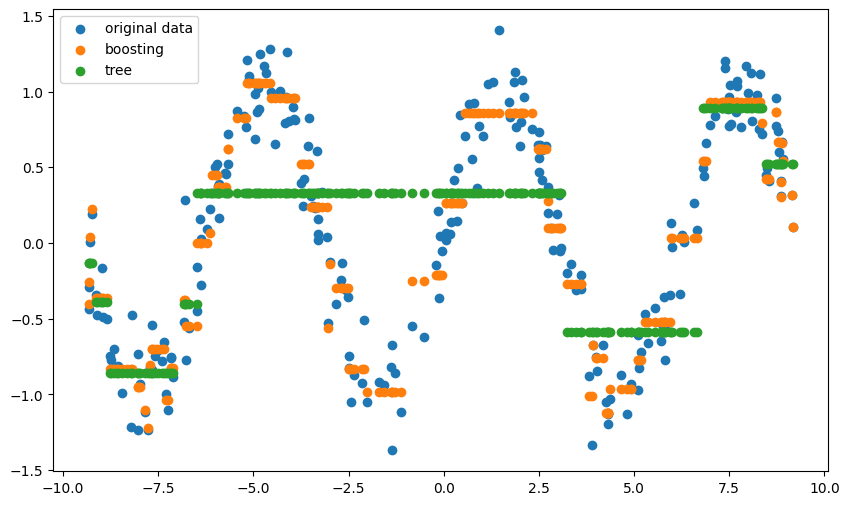

In [ ]:
# генерируем данные
np.random.seed(42)
x = np.random.uniform(low=-3*np.pi, high=3*np.pi, size=250)
y = np.sin(x) + np.random.randn(250) * 0.2

# обучаем обычное дерево глубины 3
tree = DecisionTreeRegressor(max_depth=3, random_state=42)
tree.fit(x.reshape(-1, 1), y)

# обучаем бустинг-ансамбль
clf = GradientTreeBoosting(
    loss='MSE',
    iterations=10,
    const_p=False,
    max_depth=3,
    random_state=42
)
clf.fit(x.reshape(-1, 1), y)

plt.figure(figsize=(10, 6))
plt.scatter(x, y, label='original data')
plt.scatter(x, clf.predict(x.reshape(-1, 1)), label='boosting')
plt.scatter(x, tree.predict(x.reshape(-1, 1)), label='tree')
plt.legend()
plt.show()


Примените алгоритм к тем же данным, с которыми работали в предыдущем задании для решения задачи классификации (https://www.kaggle.com/mathchi/churn-for-bank-customers). Предсказывать будем не класс (0/1), а логиты, то есть вероятность того, что клиент уйдёт, и на основе неё уже делать прогноз, определяя класс относительно некого порога (по умолчанию 0.5).

In [ ]:
def decide_class(logits, threshold=0.5):
    res = np.zeros(logits.shape[0])
    res[logits >= threshold] = 1
    return res


Сравните вашу реализацию градиентного бустинга (с константным $\rho$ и нет) с одиночным DecisionTreeRegressor по качеству и времени выполнения. При неконстантном $\rho$ качество должно возрасти.

В качестве набора данных для сравнения используйте этот датасет: https://www.kaggle.com/mathchi/churn-for-bank-customers

In [ ]:
import time
from sklearn.metrics import f1_score

X_train_b2, X_test_b2, y_train_b2, y_test_b2 = train_test_split(
    X_bank, y_bank, test_size=0.2, random_state=42, stratify=y_bank
)

y_train_reg = y_train_b2.astype(float)
y_test_reg = y_test_b2.astype(float)

models_to_compare = {
    'DecisionTreeRegressor': DecisionTreeRegressor(max_depth=3, random_state=42),
    'Boosting const rho': GradientTreeBoosting(
        loss='MSE', iterations=30, const_p=True,
        max_depth=2, random_state=42
    ),
    'Boosting optimized rho': GradientTreeBoosting(
        loss='MSE', iterations=30, const_p=False,
        max_depth=2, random_state=42
    )
}

comparison = []

for name, model in models_to_compare.items():
    start = time.perf_counter()
    model.fit(X_train_b2, y_train_reg)
    elapsed = time.perf_counter() - start
    pred = model.predict(X_test_b2)
    pred_class = decide_class(pred)

    comparison.append({
        'model': name,
        'time_sec': elapsed,
        'MAE': mae(y_test_reg, pred),
        'MSE': mse(y_test_reg, pred),
        'F1': f1_score(y_test_b2, pred_class)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)


,model,time_sec,MAE,MSE,F1
0,DecisionTreeRegressor,0.032455,0.240093,0.118823,0.374517
1,Boosting const rho,0.442593,0.324324,0.162088,0.000000
2,Boosting optimized rho,1.567836,0.221236,0.104566,0.577039


Дерево решений - своя реализация для классификации и регрессии. Протестирована на iris и на датасете продолжительности жизни. Совпадает со sklearn на одинаковых параметрах.

Случайный лес - своя реализация поверх sklearn-деревьев: бутстрап, случайные подвыборки признаков, голосование для классификации и усреднение для регрессии. Сравнён с одним деревом.

Градиентный бустинг - своя реализация с тремя функциями потерь (MSE, MAE, Lq) и двумя режимами шага: константным ρ и оптимизированным. Проверен на игрушечном примере (синусоида) и на датасете оттока клиентов.